# NIST Community Resilience: Exploratory Data Analysis

**Goal:** Compare two potential data sources for a repeatable municipal resilience-document discovery workflow, with an initial focus on Orlando, Florida.

**Exploration path:** Start with NIST TraCR indicators to evaluate geographic and temporal coverage, then examine UScityURL as a practical starting point for locating municipal websites and planning documents. These datasets serve different purposes; the comparison is about their suitability for **document discovery**, not overall data quality.

**Inputs:** Place `TraCR_v1_database.csv` and `UScityURL.csv` alongside this notebook. Required packages: `pandas`, `numpy`, `matplotlib`, `requests`, `beautifulsoup4`. Website checks require internet access and may change over time.

## 1. Setup and load TraCR

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

df = pd.read_csv("TraCR_v1_database.csv")
print("TraCR shape:", df.shape)
display(df.head())

TraCR shape: (91272, 104)


/var/folders/l8/x2rmcxms6sjc631gr0cp49cc0000gn/T/ipykernel_32932/814136149.py:6: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("TraCR_v1_database.csv")


,UID,fips,period,INFRA120001,INFRA120002,INFRA120003,INFRA120004,INFRA150001,INFRA150002,INFRA150003,...,SOCWB320018,SOCWB320019,SOCWB330014,SOCWB330015,SOCWB330016,SOCWB330017,NATENV410002,NATENV410003,NATENV410004,NATENV410005
0,1,1000,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,1000,2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,1000,2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,1000,2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,1000,2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. TraCR: structure, temporal coverage, and indicator categories

In [15]:
print("Unique geographic identifiers:", df["fips"].nunique())
print("Periods:", sorted(df["period"].dropna().unique()))
display(df.groupby("period")["fips"].nunique().rename("Geographic areas"))

Unique geographic identifiers: 8157
Periods: [2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021]


period
2000    3938
2001    4133
2002    6090
2003    4303
2004    4491
2005    4535
2006    3993
2007    5961
2008    4149
2009    3943
2010    3903
2011    4233
2012    6092
2013    3935
2014    3797
2015    3798
2016    3766
2017    3276
2018    3234
2019    3234
2020    3234
2021    3234
Name: Geographic areas, dtype: int64

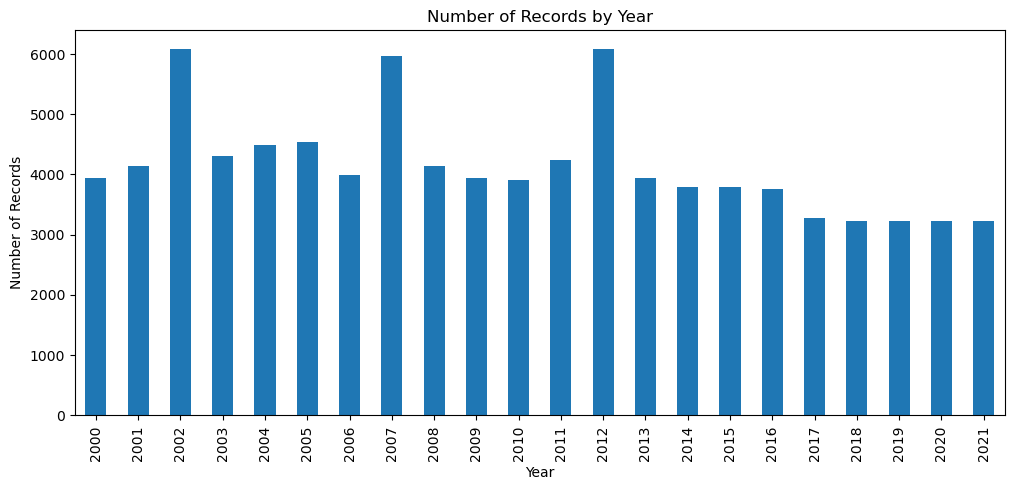

In [16]:
df['period'].value_counts().sort_index().plot(kind='bar', figsize=(12,5))

plt.title("Number of Records by Year")
plt.xlabel("Year")
plt.ylabel("Number of Records")
plt.show()

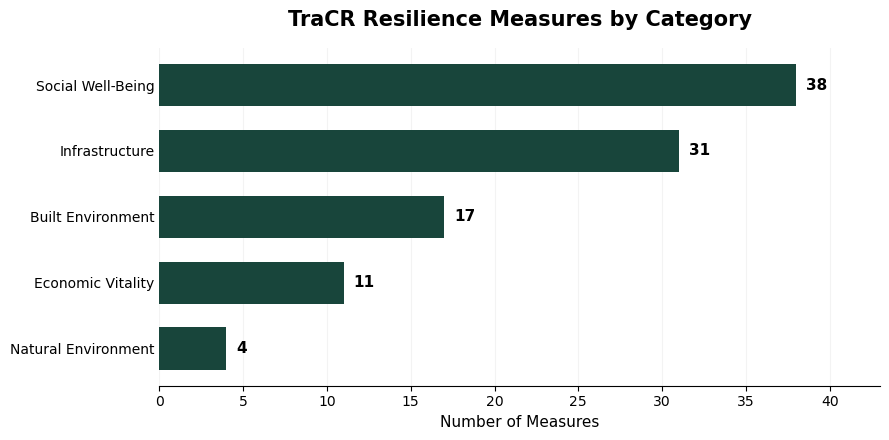

In [17]:
from pathlib import Path
Path("figures").mkdir(exist_ok=True)

# Group TraCR measures by category
categories = {
    "Infrastructure": [c for c in df.columns if c.startswith("INFRA")],
    "Social Well-Being": [c for c in df.columns if c.startswith("SOCWB")],
    "Built Environment": [c for c in df.columns if c.startswith("BLTENV")],
    "Economic Vitality": [c for c in df.columns if c.startswith("ECNVIT")],
    "Natural Environment": [c for c in df.columns if c.startswith("NATENV")]
}

category_counts = pd.Series({
    category: len(columns)
    for category, columns in categories.items()
}).sort_values()

# MSU green
msu_green = "#18453B"

fig, ax = plt.subplots(figsize=(9, 4.5))

bars = ax.barh(
    category_counts.index,
    category_counts.values,
    color=msu_green,
    height=0.65
)

# Add values at the end of each bar
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.6,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width)}",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "TraCR Resilience Measures by Category",
    fontsize=15,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Number of Measures", fontsize=11)
ax.set_xlim(0, category_counts.max() + 5)

# Clean presentation styling
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("figures/TraCR_Category_MSU.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. TraCR: missingness and Orange County pilot

Measure availability is important because many missing values can complicate comparisons across locations and years. Orange County (FIPS `12095`) is used as a county-level proxy for the Orlando area; it is **not** identical to Orlando city.

In [19]:
missing_summary = pd.DataFrame({
    'Missing': df.isna().sum(),
    'Available': df.notna().sum(),
    'Percent Missing': df.isna().mean() * 100,
    'Percent Available': df.notna().mean() * 100
})

missing_summary.sort_values('Percent Available', ascending=False)

,Missing,Available,Percent Missing,Percent Available
UID,0,91272,0.000000,100.000000
period,0,91272,0.000000,100.000000
fips,0,91272,0.000000,100.000000
ECNVIT510001,36569,54703,40.065957,59.934043
SOCWB310015,37286,53986,40.851521,59.148479
...,...,...,...,...
INFRA150017,88648,2624,97.125077,2.874923
INFRA130002,90517,755,99.172802,0.827198
SOCWB350003,90944,328,99.640635,0.359365
SOCWB350002,90944,328,99.640635,0.359365


In [20]:
measure_cols = df.columns.difference(['UID', 'fips', 'period'])

coverage = df[measure_cols].notna().mean() * 100

coverage.sort_values(ascending=False).head(20)

ECNVIT510001    59.934043
SOCWB310015     59.148479
SOCWB320017     58.533833
SOCWB320018     58.533833
SOCWB310017     58.533833
SOCWB320013     58.533833
SOCWB320016     58.533833
SOCWB320019     58.533833
INFRA120005     42.315277
INFRA120006     42.315277
INFRA120008     42.315277
BLTENV220011    42.315277
BLTENV220010    42.315277
BLTENV220009    42.315277
BLTENV220006    42.315277
BLTENV220005    42.315277
INFRA140007     40.322333
INFRA120007     38.790648
INFRA110007     19.456131
SOCWB330012     10.705364
dtype: float64

In [21]:
df["fips_clean"] = df["fips"].astype("string").str.replace(r"\.0$", "", regex=True).str.zfill(5)
florida = df[df["fips_clean"].str.startswith("12", na=False)].copy()
orange = df[df["fips_clean"] == "12095"].copy()
print("Florida rows:", len(florida), "| Orange County rows:", len(orange))
print("Orange County periods:", sorted(orange["period"].dropna().unique()))

Florida rows: 1797 | Orange County rows: 22
Orange County periods: [2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021]


In [22]:
measure_cols = [
    col for col in df.columns
    if col not in ["UID", "fips", "fips_clean", "period"]
]

orange_coverage = orange[measure_cols].notna().mean() * 100

print("Total TraCR measures:", len(measure_cols))
print("Measures with ANY Orange County data:",
      (orange_coverage > 0).sum())

print("Measures with >= 50% coverage:",
      (orange_coverage >= 50).sum())

print("Measures with 100% coverage:",
      (orange_coverage == 100).sum())

orange_coverage.sort_values(ascending=False).head(20)

Total TraCR measures: 101
Measures with ANY Orange County data: 101
Measures with >= 50% coverage: 47
Measures with 100% coverage: 0


ECNVIT510001    77.272727
SOCWB310017     77.272727
SOCWB310015     77.272727
SOCWB320019     77.272727
SOCWB320018     77.272727
SOCWB320013     77.272727
SOCWB320017     77.272727
SOCWB320016     77.272727
BLTENV220006    54.545455
BLTENV220001    54.545455
BLTENV220002    54.545455
BLTENV220003    54.545455
BLTENV220004    54.545455
BLTENV220005    54.545455
INFRA120005     54.545455
BLTENV220007    54.545455
ECNVIT530001    54.545455
INFRA120006     54.545455
INFRA120008     54.545455
BLTENV220008    54.545455
dtype: float64

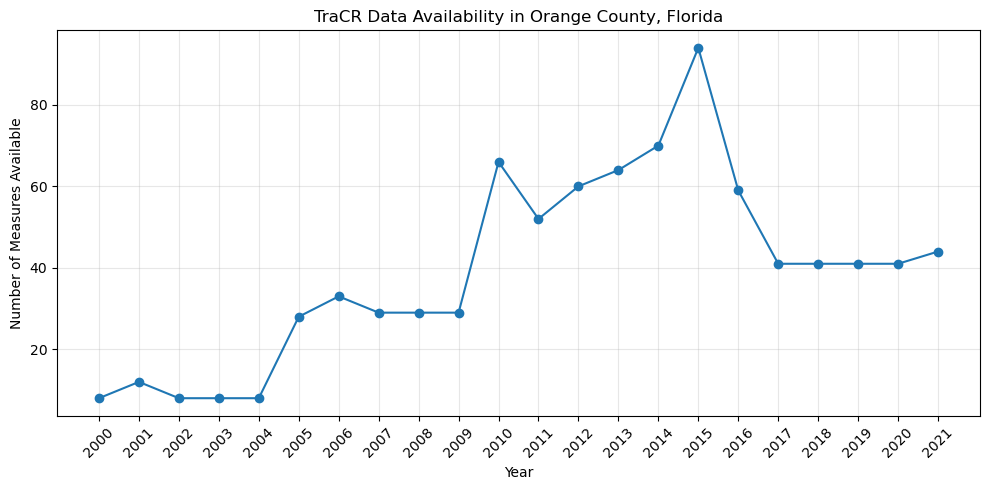

In [23]:
year_coverage = orange.set_index("period")[measure_cols].notna().sum(axis=1)

import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(
    year_coverage.index,
    year_coverage.values,
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Number of Measures Available")
plt.title("TraCR Data Availability in Orange County, Florida")
plt.xticks(year_coverage.index, rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

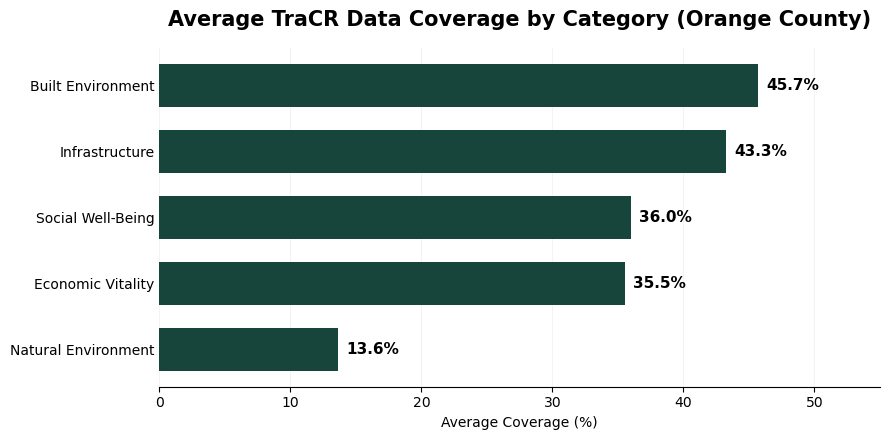

In [24]:
from pathlib import Path
Path("figures").mkdir(exist_ok=True)

categories = {
    "Infrastructure": "INFRA",
    "Social Well-Being": "SOCWB",
    "Built Environment": "BLTENV",
    "Economic Vitality": "ECNVIT",
    "Natural Environment": "NATENV"
}

coverage = {}

for category, prefix in categories.items():
    cols = [c for c in measure_cols if c.startswith(prefix)]
    coverage[category] = orange[cols].notna().mean().mean() * 100

coverage = pd.Series(coverage).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.5))

bars = ax.barh(
    coverage.index,
    coverage.values,
    color="#18453B",
    height=0.65
)

for bar in bars:
    ax.text(
        bar.get_width() + 0.6,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}%",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Average TraCR Data Coverage by Category (Orange County)",
    fontsize=15,
    fontweight="bold",
    pad=16
)
ax.set_xlabel("Average Coverage (%)")
ax.set_xlim(0, 55)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis="y", length=0)

plt.tight_layout()
plt.savefig("figures/TraCR_Coverage_MSU.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation:** Coverage varies by measure and category. Missingness makes TraCR less convenient as the primary source for locating planning documents, although its quantitative indicators may support later resilience analysis. Indicator codes should be matched to official metadata before interpreting trends.

## 4. Transition: from indicators to municipal website discovery

TraCR provides resilience-related measures but not a ready-made directory of municipal planning documents. The next exploration uses **UScityURL**, which offers municipality names and website links—a more direct starting point for discovering planning documents. Website availability alone does not prove a site contains relevant or current plans.

## 5. UScityURL: basic quality checks

In [28]:
city_urls = pd.read_csv("UScityURL.csv")

print("Shape:", city_urls.shape)
print("\nColumns:")
print(city_urls.columns.tolist())

display(city_urls.head())

Shape: (19518, 5)

Columns:
['GEOID', 'MUNICIPALITY', 'STATE', 'WEBSITE_AVAILABLE', 'WEBSITE_URL']


,GEOID,MUNICIPALITY,STATE,WEBSITE_AVAILABLE,WEBSITE_URL
0,1600000US3651000,New York,New York,1,https://www.nyc.gov/
1,1600000US0644000,Los Angeles,California,1,https://www.lacity.org/
2,1600000US1714000,Chicago,Illinois,1,https://www.chicago.gov/
3,1600000US4835000,Houston,Texas,1,http://www.houstontx.gov/
4,1600000US0455000,Phoenix,Arizona,1,https://www.phoenix.gov/


In [29]:
print("Missing values:")
display(city_urls.isna().sum())

print("\nDuplicate rows:", city_urls.duplicated().sum())

print("\nWebsite availability:")
display(city_urls["WEBSITE_AVAILABLE"].value_counts(dropna=False))

print("\nUnique states:", city_urls["STATE"].nunique())
print("Unique municipalities:", city_urls["MUNICIPALITY"].nunique())

Missing values:


GEOID                   0
MUNICIPALITY            0
STATE                   0
WEBSITE_AVAILABLE       0
WEBSITE_URL          5795
dtype: int64


Duplicate rows: 0

Website availability:


WEBSITE_AVAILABLE
1    13723
0     5795
Name: count, dtype: int64


Unique states: 50
Unique municipalities: 12696


## 6. Florida and Orlando focus

In [31]:
florida_cities = city_urls[city_urls["STATE"] == "Florida"].copy()

print("Florida municipalities:", len(florida_cities))
print("Florida municipalities with websites:",
      florida_cities["WEBSITE_URL"].notna().sum())

print("Website coverage:",
      round(florida_cities["WEBSITE_URL"].notna().mean() * 100, 1), "%")

display(florida_cities.head(10))

Florida municipalities: 412
Florida municipalities with websites: 388
Website coverage: 94.2 %


,GEOID,MUNICIPALITY,STATE,WEBSITE_AVAILABLE,WEBSITE_URL
11,1600000US1235000,Jacksonville,Florida,1,https://www.coj.net/
42,1600000US1245000,Miami,Florida,1,https://www.miamigov.com/
51,1600000US1271000,Tampa,Florida,1,https://tampagov.net/
65,1600000US1253000,Orlando,Florida,1,https://www.orlando.gov/
83,1600000US1263000,St. Petersburg,Florida,1,https://www.stpete.org/
99,1600000US1230000,Hialeah,Florida,1,https://www.hialeahfl.gov/
112,1600000US1258715,Port St. Lucie,Florida,1,https://www.cityofpsl.com/
125,1600000US1270600,Tallahassee,Florida,1,https://talgov.com/
128,1600000US1210275,Cape Coral,Florida,1,https://www.capecoral.net/
139,1600000US1224000,Fort Lauderdale,Florida,1,https://www.fortlauderdale.gov/


In [32]:
orlando = florida_cities[
    florida_cities["MUNICIPALITY"]
    .str.contains("Orlando", case=False, na=False)
]

display(orlando)

,GEOID,MUNICIPALITY,STATE,WEBSITE_AVAILABLE,WEBSITE_URL
65,1600000US1253000,Orlando,Florida,1,https://www.orlando.gov/


In [33]:
pilot_city_names = [
    "Orlando",
    "Tampa",
    "Miami",
    "Jacksonville",
    "St. Petersburg"
]

pilot_cities = florida_cities[
    florida_cities["MUNICIPALITY"]
    .str.lower()
    .isin([city.lower() for city in pilot_city_names])
].copy()

pilot_cities = pilot_cities[
    ["GEOID", "MUNICIPALITY", "STATE", "WEBSITE_AVAILABLE", "WEBSITE_URL"]
]

display(pilot_cities)

,GEOID,MUNICIPALITY,STATE,WEBSITE_AVAILABLE,WEBSITE_URL
11,1600000US1235000,Jacksonville,Florida,1,https://www.coj.net/
42,1600000US1245000,Miami,Florida,1,https://www.miamigov.com/
51,1600000US1271000,Tampa,Florida,1,https://tampagov.net/
65,1600000US1253000,Orlando,Florida,1,https://www.orlando.gov/
83,1600000US1263000,St. Petersburg,Florida,1,https://www.stpete.org/


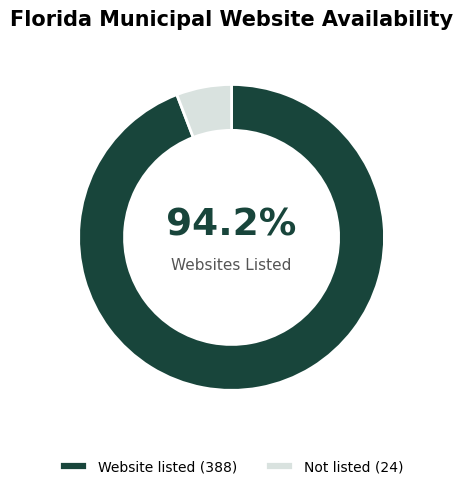

In [34]:
from pathlib import Path
Path("figures").mkdir(exist_ok=True)

# Florida municipal website availability
with_website = florida_cities["WEBSITE_URL"].notna().sum()
without_website = len(florida_cities) - with_website

msu_green = "#18453B"
light_gray = "#D9E2DF"

fig, ax = plt.subplots(figsize=(7, 5))

wedges, _ = ax.pie(
    [with_website, without_website],
    colors=[msu_green, light_gray],
    startangle=90,
    counterclock=False,
    wedgeprops={"width": 0.30, "edgecolor": "white", "linewidth": 2}
)

percentage = with_website / len(florida_cities) * 100

ax.text(
    0, 0.08, f"{percentage:.1f}%",
    ha="center", va="center",
    fontsize=27, fontweight="bold", color=msu_green
)

ax.text(
    0, -0.18, "Websites Listed",
    ha="center", va="center",
    fontsize=11, color="#555555"
)

ax.legend(
    wedges,
    [f"Website listed ({with_website})",
     f"Not listed ({without_website})"],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.15),
    frameon=False,
    ncol=2
)

ax.set_title(
    "Florida Municipal Website Availability",
    fontsize=15, fontweight="bold", pad=15
)

plt.tight_layout()
plt.savefig("figures/UScityURL_Florida_Coverage.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 7. Pilot document discovery from Orlando

The following cells make a **live HTTP request** to the Orlando municipal website. Results may vary with site changes, redirects, rate limits, or blocked requests. Keyword matching is a preliminary screen—not verification that a link is a resilience plan.

In [36]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

if orlando.empty or orlando["WEBSITE_URL"].dropna().empty:
    raise ValueError("No Orlando website URL was found in UScityURL.csv")

url = orlando["WEBSITE_URL"].dropna().iloc[0]
response = requests.get(url, headers={"User-Agent": "Mozilla/5.0 (academic research)"}, timeout=10)
response.raise_for_status()
soup = BeautifulSoup(response.text, "html.parser")
orlando_links = pd.DataFrame([{"text": a.get_text(" ", strip=True), "url": urljoin(response.url, a["href"])} for a in soup.find_all("a", href=True)]).drop_duplicates()
print("Links found on landing page:", len(orlando_links))
display(orlando_links.head(20))

Links found on landing page: 655


,text,url
0,Skip to main content,https://www.orlando.gov/Home#main-content
1,English Select this as your preferred language,https://www.orlando.gov/Home?oc_lang=en-US
3,,https://www.orlando.gov/Home
4,Home,https://www.orlando.gov/Home
5,Report a Problem,https://www.orlando.gov/Report-a-Problem
6,Non-Violent Crimes,https://www.orlando.gov/Report-a-Problem/Repor...
7,Code Enforcement,https://www.orlando.gov/Report-a-Problem/Repor...
8,Streets and Traffic,https://www.orlando.gov/Report-a-Problem/Repor...
9,Report a Pothole,https://www.orlando.gov/Report-a-Problem/Repor...
10,Report a Broken Sidewalk,https://www.orlando.gov/Report-a-Problem/Repor...


In [37]:
keywords = [
    "resilien",
    "climate",
    "sustainab",
    "hazard",
    "emergency",
    "flood",
    "hurricane",
    "adaptation",
    "future-ready",
    "comprehensive plan"
]

pattern = "|".join(keywords)

relevant_links = orlando_links[
    orlando_links["text"].str.contains(pattern, case=False, na=False) |
    orlando_links["url"].str.contains(pattern, case=False, na=False)
].copy()

print("Potential resilience-related links:", len(relevant_links))

display(relevant_links)

Potential resilience-related links: 15


,text,url
20,Report Flooding,https://www.orlando.gov/Report-a-Problem/Repor...
49,The Emergency Operations Center Building Expan...,https://www.orlando.gov/Building-Development/C...
68,Floodplain Management Plan Study,https://www.orlando.gov/Building-Development/C...
99,Community Development Block Grants & Emergency...,https://www.orlando.gov/Building-Development/H...
347,Find out if you live in a Floodplain,https://www.orlando.gov/Parks-the-Environment/...
373,Become a Police Department Emergency Communica...,https://www.orlando.gov/Public-Safety/OPD/Beco...
397,Submit Emergency Radio Signal Surveys,https://www.orlando.gov/Public-Safety/OFD/Subm...
442,"Volunteer with the Office of Sustainability, R...",https://www.orlando.gov/Community-Programs-Eve...
596,Orlando plans for a future-ready city,https://www.orlando.gov/Our-Government/Orlando...
597,Small Cell and 5G Technology,https://www.orlando.gov/Our-Government/Orlando...


In [38]:
pdf_links = orlando_links[
    orlando_links["url"].str.contains(r"\.pdf($|\?)", case=False, na=False, regex=True)
].copy()

print("PDF links found:", len(pdf_links))
display(pdf_links)

PDF links found: 0


/var/folders/l8/x2rmcxms6sjc631gr0cp49cc0000gn/T/ipykernel_32932/3229519552.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  orlando_links["url"].str.contains(r"\.pdf($|\?)", case=False, na=False, regex=True)


,text,url


## 8. Conclusions and next steps

- **TraCR:** Useful for quantitative resilience indicators, but missing measures, coded variable names, and county-level geography complicate direct use in a municipal document-discovery workflow.
- **UScityURL:** More directly useful for the initial workflow because it provides municipal website entry points, including Florida municipalities.
- **Limitations:** The URL list does not itself identify or validate planning documents. Landing-page scraping can miss documents deeper in a website, and keyword matches can include irrelevant pages.
- **Next steps:** Follow relevant links beyond the homepage, identify actual PDFs and planning documents, record metadata and source URLs, and manually verify a sample before scaling the process.

**Reproducibility:** Run cells top to bottom with both CSV inputs available. The live website section may fail if the website is unavailable; previous dataset analysis remains usable.